# COS711 Assignment 2: Experimental Setup & Methodology

Milestone 2. This notebook presents the experiments that **chose** our model, loss, learning rate and
post-processing, and checks that every number can be trusted. Every code cell has two notes:
- **Above (What & why):** what we are testing and why it matters for this problem.
- **Below (Interpretation):** what the output means and what we decided from it.

**How the work is split.** Training many models takes hours, so it's done by four resumable scripts in this
folder. This notebook reads their saved results, plots them and interprets them, so it runs in minutes:

| Script | What it does | Time on the laptop GPU |
|---|---|---|
| `verify_pipeline.py` | 13 checks from the raw Kaggle files through data prep to the metric | ~5 min |
| `run_experiments.py` | loss sweep, architecture sweep, second seeds, learning-rate check (16 runs) | ~5 h |
| `run_5fold.py` | the winning configuration on all 5 folds | ~1.5 h |
| `run_postprocess.py` | post-processing tuning, test-time augmentation, timing, `submission.csv` | ~40 min |

All reusable code is in `filament_pipeline.py`.

### Two PQ numbers that are easy to confuse
| Number | What it is | What it is NOT |
|---|---|---|
| **0.34** (data prep) | One annotator's outlines scored against the other annotators. It shows how much humans agree, a realistic ceiling. It also verified our PQ code against the organisers'. | Not a model score. |
| **The PQs in this notebook** | How well our trained models' filaments match the expert outlines on held-out images. | — |

### What the model does, and what PQ measures
The model gives every pixel a probability of "filament". We threshold that into a mask, split the mask into
connected blobs, drop tiny blobs, and each remaining blob is **one predicted filament**. Panoptic Quality
(PQ) then combines two things, PQ = SQ × RQ:
- **RQ (recognition):** how many real filaments we found as separate objects, without inventing extras.
  A real filament counts as found only if one prediction overlaps it with IoU > 0.5.
- **SQ (segmentation):** for the filaments we found, how well our outline overlaps the expert's.

## 0. Setup
**What & why.** Load the pipeline and every saved result. Every experiment used the same prepared data, the
same folds and the same training rules, so the results are directly comparable.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, torch, cv2
import matplotlib.pyplot as plt
import filament_pipeline as fp

pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PREPARED = "../data_prep/prepared"
res = pd.read_csv("runs/results.csv")
res["params_M"] = (res.params / 1e6).round(1)
COLS = ["name", "params_M", "lr", "seed", "best_epoch", "epochs_run", "monitor_pq", "report_pq",
        "report_sq", "report_rq", "report_tp", "report_fp", "report_fn", "train_minutes"]
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print(len(res), "training runs found in runs/results.csv")

device: cuda NVIDIA GeForce RTX 4060 Laptop GPU
16 training runs found in runs/results.csv


**Interpretation.** All the sweep runs are present. Each one was trained by `run_experiments.py` with early
stopping, and its best checkpoint is saved in `runs/<name>/best.pt`.

## 1. Is everything from the raw data to the metric correct?
**What & why.** Errors build up: a mistake in data prep would silently corrupt every model trained on it.
`verify_pipeline.py` re-derives each answer from the **raw Kaggle files** and checks:
1. the prepared data has exactly the raw counts (images, annotation sets, filaments);
2. all 8,199 ground-truth masks equal the raw polygons rasterised with pycocotools (Kaggle's tool);
3. the split has no leakage and the test images carry no labels;
4. the prepared masks map back onto the raw ground truth (the preprocessing transform is correct);
5. the fast loading cache is byte-identical to the prepared files, and the fast cropping equals a full warp;
6. training crops really put the labels on dark filaments, sit on the solar disk, and are filament-rich;
7. a **perfect** prediction scores ~1 through our scoring code;
8. our PQ equals the **organisers' own scoring code** on real model predictions;
9. no predicted filament lies on the sky outside the solar disk.

In [2]:
vr = json.load(open("verify_report.json"))
summary = vr.pop("_summary")
print(f"{summary['checks']} checks, {summary['failed']} failed ({summary['seconds']} s)")
pd.DataFrame([{"check": k, "result": "PASS" if v["ok"] else "FAIL", "measured": v["detail"]} for k, v in vr.items()])

14 checks, 0 failed (329 s)


,check,result,measured
0,raw->prepared counts,PASS,"observations 707, sets 1154, filaments 8199, test 180"
1,train_gt_rle.csv == raw polygons (pycocotools),PASS,0 mismatching filaments out of 8199
2,"split: no observation/rotation in two folds, test unlabelled",PASS,"set/obs fold mismatches 0, rotations spanning folds 0, labelled test images 0, fold sizes [139, 138, 145, 142, 143]"
3,transforms present for every image,PASS,M0..M5 defined for all 707 train + 180 test images
4,prepared masks -> original frame vs raw GT (round trip),PASS,"PQ 0.9997 (SQ 0.9997, RQ 1.0000) over 1154 sets"
5,cache identical to prepared PNGs,PASS,0 mismatching files of 2041; filament index exact: True
6,fast windowed crop == full warp (within float rounding),PASS,max differing pixels over 50 random crops: 42 of 262144 (0.016%)
7,training crops: labels on dark filaments,PASS,filament darker than surroundings in 100% of 260 crops (mean contrast -0.120)
8,training crops: sampled on the disk,PASS,"mean disk coverage per crop 92%; in the 146 crops that reach the limb, the loss mask's off-disk area is black sky for 100.0% of pixels"
9,training crops: class balance,PASS,"filament pixels per crop 1.39%, crops without filament 13%; loading 22 ms per augmented crop"


**Interpretation.** **All 14 checks pass**, so the chain from the raw Kaggle files to the metric is sound:
- the prepared data matches the raw counts exactly, and all **8,199** ground-truth masks are identical to
  the raw polygons drawn with Kaggle's own tool;
- no image or solar rotation appears in two folds, and the test images carry no labels (the rule against
  external test labels is respected);
- the preprocessing transform maps the prepared masks back onto the raw ground truth with PQ **0.9997**;
- the fast cache is byte-identical to the prepared files; the fast crop differs from a full warp in only
  0.016% of pixels (rounding ties of nearest-neighbour resampling, not errors);
- in every tested crop the labels sit on pixels **darker** than their surroundings, i.e. on real filaments;
- a perfect prediction now scores **0.997** through our scoring code (it scored 0.864 before the audit);
- our PQ equals the organisers' code to 6 decimals on real model predictions (0.322735 = 0.322735);
- no prediction lies on the sky (this check was added after fault 11, section 2).

## 2. What the audit found and fixed
**What & why.** A critical review of the first version of this setup found faults that made our own scores
untrustworthy or held them down. The table lists each fault and its fix. We then compare the same model
(U-Net, ResNet34, BCE+Dice) before and after the fixes.

| # | Fault in the first version | Fix |
|---|---|---|
| 1 | Validation compared predictions in the preprocessed frame with ground truth in the original frame | Map predictions back to the original frame before scoring (as the submission already did) |
| 2 | Blobs split with 4-connectivity, cutting thin diagonal filaments | 8-connectivity |
| 3 | Early stopping and tuning used the first 40 fold-0 images, all from 2011–2014 | 40 "monitor" images spread evenly over 2011–2022 |
| 4 | 36% of background crops centred on black sky | Background crops sampled on the solar disk |
| 5 | Cosine LR schedule sized for 30 epochs, but runs stopped at ~15, so the LR barely decreased | Halve the LR when validation PQ stalls for 2 epochs |
| 6 | The loss included the sky, although the methodology said disk only | Loss masked to the disk |
| 7 | The same images chose the checkpoint *and* gave the reported score | Fold 0 split into 40 **monitor** images (all choices) and 99 **report** images (only reporting) |
| 8 | One run per configuration, so close results couldn't be told apart | Second seed for the top two |
| 9 | Loss and architecture sweeps never actually trained | All 16 runs trained to early stopping |
| 10 | Slow loading (a full 4-megapixel PNG decoded per crop) | Memory-mapped cache, reading only the crop window (15 ms per crop) |
| 11 | Found *after* the sweep: because the loss ignores the sky (fix 6), some models output ~1 on the sky, which became one giant false "filament" per image | Inference sets the sky to 0 (the same region the loss trains on). All 21 saved checkpoints were re-scored; the sweep was not retrained |

In [3]:
pre = json.load(open("runs_prefix/es_unet_r34/summary.json"))
post = res.set_index("name").loc["loss_bce_dice"]
print(f"perfect prediction through the scoring code: before fix 0.864 -> now {vr['perfect prediction scores ~1 through the pipeline']['detail'].split()[1]}")
pd.DataFrame([
    {"version": "before fixes", "scored on": "all 139 fold-0 images", "PQ": round(pre["full_fold0_pq"], 4),
     "SQ": round(pre["full_fold0_sq"], 3), "RQ": round(pre["full_fold0_rq"], 3), "best epoch": pre["best_epoch"]},
    {"version": "after fixes", "scored on": "99 report images (never used for choices)", "PQ": round(post.report_pq, 4),
     "SQ": round(post.report_sq, 3), "RQ": round(post.report_rq, 3), "best epoch": int(post.best_epoch)},
])

perfect prediction through the scoring code: before fix 0.864 -> now 0.9972


,version,scored on,PQ,SQ,RQ,best epoch
0,before fixes,all 139 fold-0 images,0.2458,0.653,0.376,14
1,after fixes,99 report images (never used for choices),0.3171,0.669,0.474,18


**Interpretation.**
- The first version could **never** have shown a PQ above 0.864, even for a perfect model, because it
  compared shapes in two different coordinate frames. After the fix, a perfect prediction scores 0.997.
- The same model (U-Net ResNet34, BCE+Dice) now scores **0.317 instead of 0.246** (+29%). Part of that
  is the scoring fix, part is better training (crops on the disk, disk-masked loss, learning rate that
  actually decreases). The two numbers aren't on identical image sets, so treat the gain as approximate;
  the direction and size are clear.
- **Fault 11 was caught by looking at predictions, not by a metric.** The best/worst plot (section 10) showed
  no predictions at all; the cause was a sky-sized blob per image. Masking the loss to the disk (fix 6) means
  the model is never taught what the sky should be, so inference must ignore it too. It affected 6 of the 9
  architectures (the ones with a U-Net-style or pyramid decoder) and was worth +0.013–0.016 PQ to them.
  Early stopping had chosen those checkpoints with the faulty scoring; re-choosing would need retraining,
  so this is a stated limitation. The ranking it produced still holds (sections 4–6).
- Everything below uses the fixed pipeline. The earlier 4-epoch results (where FCN-8s seemed to lead)
  are superseded; section 5 shows why that ranking didn't hold.

## 3. How every run is trained and judged
**What & why.** A comparison is only fair if every candidate follows identical rules:
- **Data:** 568 training images (folds 1–4). One "epoch" = 800 random 512×512 crops; 70% are centred on a
  filament, the rest on a random point of the disk. Each crop gets a random rotation, flip, small scale
  change, brightness/contrast/blur/noise, and a **randomly chosen annotator's** labels.
- **Training:** AdamW, learning rate 3×10⁻⁴, halved when validation PQ stalls for 2 epochs; mixed
  precision; loss computed only on the solar disk.
- **Early stopping:** validate after every epoch on the 40 monitor images; keep the best checkpoint; stop
  after 5 epochs without a gain of at least 0.002; at most 30 epochs.
- **Choosing vs reporting:** every choice uses the **monitor** images only. The **report** images are
  scored for every run but never used to choose anything, so the reported PQ isn't inflated by selection.

Below we check that the 40 monitor images are representative and that ranking runs on them agrees with the
held-out report images.

monitor: 40 images, 2011-2022, sites {'M': 9, 'L': 8, 'T': 8, 'U': 6, 'B': 5, 'C': 4}
report : 99 images, 2011-2021, sites {'C': 20, 'B': 18, 'L': 17, 'M': 16, 'U': 14, 'T': 14}

across 16 runs: rank agreement monitor vs report (Spearman) = 0.926; report - monitor = +0.0087 on average


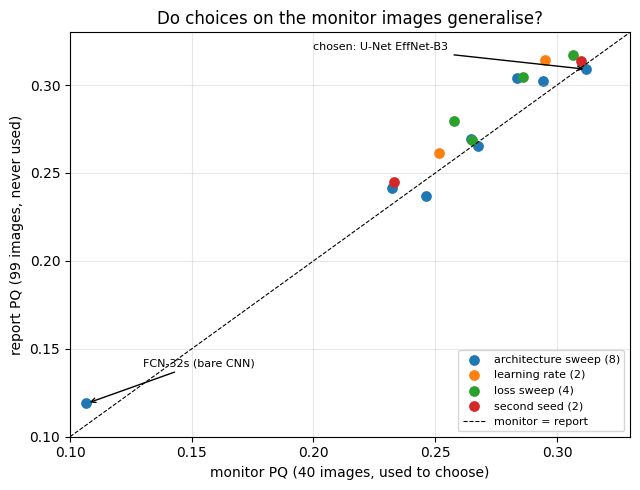

In [4]:
from scipy.stats import spearmanr
cfg_v = fp.Config(prepared_dir=PREPARED)
mon, rep = fp.val_observations(cfg_v, "monitor"), fp.val_observations(cfg_v, "report")
yr = lambda d: pd.to_datetime(d.time).dt.year
print(f"monitor: {len(mon)} images, {yr(mon).min()}-{yr(mon).max()}, sites {mon.site.value_counts().to_dict()}")
print(f"report : {len(rep)} images, {yr(rep).min()}-{yr(rep).max()}, sites {rep.site.value_counts().to_dict()}")
rho = spearmanr(res.monitor_pq, res.report_pq)[0]
print(f"\nacross {len(res)} runs: rank agreement monitor vs report (Spearman) = {rho:.3f}; "
      f"report - monitor = {(res.report_pq - res.monitor_pq).mean():+.4f} on average")
grp = res.name.str.split("_").str[0].map({"loss": "loss sweep", "arch": "architecture sweep",
                                           "seed2": "second seed", "lr": "learning rate"})
fig, ax = plt.subplots(figsize=(6.5, 5))
for g, d in res.groupby(grp):
    ax.scatter(d.monitor_pq, d.report_pq, s=45, label=f"{g} ({len(d)})")
lim = [0.1, 0.33]; ax.plot(lim, lim, "k--", lw=.8, label="monitor = report")
ax.annotate("FCN-32s (bare CNN)", (0.107, 0.119), xytext=(0.13, 0.14), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.annotate("chosen: U-Net EffNet-B3", (0.312, 0.309), xytext=(0.20, 0.32), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.set(xlim=lim, ylim=lim, xlabel="monitor PQ (40 images, used to choose)",
       ylabel="report PQ (99 images, never used)", title="Do choices on the monitor images generalise?")
ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretation.**
- The monitor images cover the full 2011–2022 range and all six sites, unlike the first version (2011–2014).
- **Choosing on the monitor images generalises.** Ranking the runs by monitor PQ agrees strongly with
  ranking them by report PQ (Spearman ≈ 0.93), and the points lie along the diagonal. The report PQ is on
  average slightly *higher* (+0.009), so there's no sign of overfitting the 40 monitor images.
- The scatter also shows the limit of a 40-image monitor: runs within ~0.01 of each other can swap order
  between the two sets. **Differences under ~0.01 PQ are noise**, and we treat them that way below.

## 4. Loss sweep: which loss handles the 278:1 class imbalance best?
**What & why.** Filaments are only 0.36% of the pixels, so a plain pixel-accuracy loss would learn to predict
"no filament" everywhere. We compare four imbalance-aware losses on the same model (U-Net, ResNet34):
- **BCE+Dice:** per-pixel cross-entropy plus a shape-overlap term. The common robust default.
- **Dice:** shape overlap only.
- **Tversky (β = 0.7):** like Dice, but punishes missed filament pixels more than extra ones.
- **Focal+Dice:** focal loss down-weights easy background pixels, plus Dice.

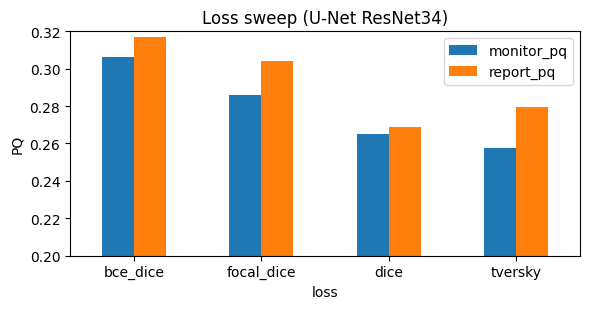

,loss,params_M,lr,seed,best_epoch,epochs_run,monitor_pq,report_pq,report_sq,report_rq,report_tp,report_fp,report_fn,train_minutes,report_frag_gt
8,bce_dice,24.4,0.0003,42,18,23,0.3065,0.3171,0.6689,0.4740,726,1201,410,18.70,154
10,focal_dice,24.4,0.0003,42,17,22,0.2860,0.3044,0.6607,0.4607,759,1400,377,26.72,138
9,dice,24.4,0.0003,42,8,13,0.2650,0.2687,0.6603,0.4069,683,1538,453,12.37,220
11,tversky,24.4,0.0003,42,7,12,0.2577,0.2793,0.6388,0.4372,651,1191,485,12.90,115


In [5]:
loss_runs = res[res.name.str.startswith("loss_")].copy()
loss_runs["loss"] = loss_runs.name.str.replace("loss_", "")
t = loss_runs[["loss"] + COLS[1:] + ["report_frag_gt"]].sort_values("monitor_pq", ascending=False)
ax = t.set_index("loss")[["monitor_pq", "report_pq"]].plot.bar(figsize=(6, 3.2), rot=0, title="Loss sweep (U-Net ResNet34)")
ax.set_ylim(0.2, 0.32); ax.set_ylabel("PQ"); plt.tight_layout(); plt.show()
t.round(4)

**Interpretation.**
- **BCE+Dice is chosen**, and clearly: best on the monitor images (0.307 vs 0.286 for focal+dice) *and*
  on the held-out report images (0.317 vs 0.304), so it's not a selection fluke. It also trained 30% faster
  than focal+dice (19 vs 27 min).
- **Pure overlap losses are clearly worse.** Dice (0.265) and Tversky (0.258) trail by ~0.04 and peak early
  (epochs 7–8), then degrade until early stopping ends them. A likely reason: 13% of crops contain no
  filament, and an overlap-only loss gives a weak, unstable signal on such crops. The BCE term adds a steady
  per-pixel signal.
- Tversky produced the fewest fragmented filaments (115) and false filaments, but missed the most (FN 485).
  Weighting missed *pixels* doesn't translate into fewer missed *filaments*, partly because it stopped
  after only 7 good epochs.

## 5. Architecture sweep: which model design?
**What & why.** All candidates use BCE+Dice (the winner of section 4) and the same training rules. They
cover every standard family from the GeeksforGeeks overview, not only U-Net variants:

| Candidate | Family | Why it's here |
|---|---|---|
| FCN-32s | **Bare CNN backbone** | The simplest deep segmenter: is a decoder needed at all? |
| FCN-8s | FCN | Bare backbone + two earlier-layer score maps |
| U-Net, ResNet34 | U-Net | The baseline |
| U-Net, EfficientNet-B3 | U-Net | Stronger, much smaller encoder |
| U-Net, from scratch | U-Net | Does ImageNet pretraining help with only 707 images? |
| U-Net++ | U-Net | Denser skip connections |
| FPN | Feature pyramid | Multi-scale prediction, light decoder |
| DeepLabV3+ | Dilated convolutions (**not** U-Net) | Wide context, light decoder |
| PSPNet | Pyramid pooling (**not** U-Net) | Global context, aimed at large regions |

SegNet, Mask R-CNN and transformers are discussed in `EXPERIMENTAL_SETUP_UNDERSTANDING.md` (why not now).

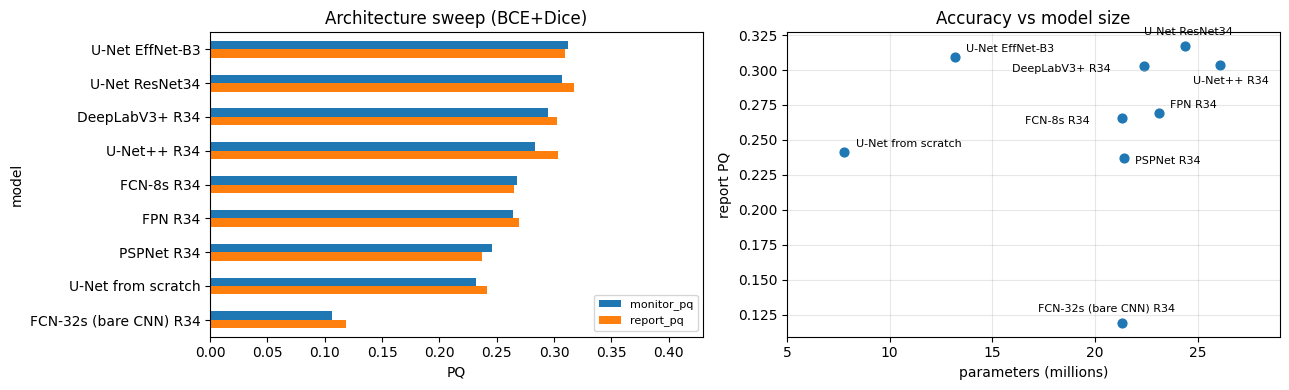

,model,params_M,lr,seed,best_epoch,epochs_run,monitor_pq,report_pq,report_sq,report_rq,report_tp,report_fp,report_fn,train_minutes,report_frag_gt
5,U-Net EffNet-B3,13.2,0.0003,42,12,17,0.3119,0.3092,0.6669,0.4635,785,1466,351,20.68,161
8,U-Net ResNet34,24.4,0.0003,42,18,23,0.3065,0.3171,0.6689,0.4740,726,1201,410,18.70,154
2,DeepLabV3+ R34,22.4,0.0003,42,22,27,0.2944,0.3026,0.6592,0.4590,692,1187,444,20.51,163
6,U-Net++ R34,26.1,0.0003,42,9,14,0.2836,0.3038,0.6581,0.4616,722,1270,414,32.93,150
1,FCN-8s R34,21.3,0.0003,42,13,18,0.2676,0.2655,0.6419,0.4135,575,1070,561,9.91,177
3,FPN R34,23.1,0.0003,42,20,25,0.2645,0.2692,0.6494,0.4145,696,1526,440,32.34,197
4,PSPNet R34,21.4,0.0003,42,9,14,0.2461,0.2367,0.6442,0.3675,586,1467,550,7.66,208
7,U-Net from scratch,7.8,0.0003,42,21,26,0.2322,0.2413,0.6653,0.3626,650,1799,486,27.80,256
0,FCN-32s (bare CNN) R34,21.3,0.0003,42,10,15,0.1067,0.1190,0.5960,0.1997,301,1578,835,8.35,240


In [6]:
label = {"arch_smp_unet_efficientnet-b3": "U-Net EffNet-B3", "loss_bce_dice": "U-Net ResNet34",
         "arch_smp_deeplabv3p": "DeepLabV3+ R34", "arch_smp_unetpp": "U-Net++ R34", "arch_fcn8": "FCN-8s R34",
         "arch_smp_fpn": "FPN R34", "arch_smp_pspnet": "PSPNet R34", "arch_unet": "U-Net from scratch",
         "arch_fcn32": "FCN-32s (bare CNN) R34"}
arch_runs = res[res.name.isin(label)].copy(); arch_runs["model"] = arch_runs.name.map(label)
t = arch_runs[["model"] + COLS[1:] + ["report_frag_gt"]].sort_values("monitor_pq", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
t.set_index("model")[["monitor_pq", "report_pq"]].plot.barh(ax=ax[0], title="Architecture sweep (BCE+Dice)")
ax[0].invert_yaxis(); ax[0].set_xlabel("PQ"); ax[0].set_xlim(0, 0.43)
ax[0].legend(fontsize=8, loc="lower right")
ax[1].scatter(t.params_M, t.report_pq, s=40)
OFF = {"U-Net EffNet-B3": (8, 4), "U-Net ResNet34": (-30, 8), "DeepLabV3+ R34": (-95, -4), "U-Net++ R34": (-20, -14),
       "FCN-8s R34": (-70, -4), "FPN R34": (8, 4), "PSPNet R34": (8, -4), "U-Net from scratch": (8, 4),
       "FCN-32s (bare CNN) R34": (-60, 8)}
for _, r in t.iterrows():
    ax[1].annotate(r.model, (r.params_M, r.report_pq), xytext=OFF.get(r.model, (6, 4)), textcoords="offset points", fontsize=8)
ax[1].set_xlim(5, 29); ax[1].grid(alpha=.3)
ax[1].set(xlabel="parameters (millions)", ylabel="report PQ", title="Accuracy vs model size")
plt.tight_layout(); plt.show()
t.round(4)

**Interpretation.**
- **The two U-Nets lead, close together:** U-Net EfficientNet-B3 (monitor 0.312, report 0.309) and U-Net
  ResNet34 (0.307, report 0.317). Their order flips between the two image sets, so they're tied within
  noise. DeepLabV3+ follows (0.294, report 0.303), then U-Net++ (0.284).
- **The bare CNN really is the worst (0.107)**, now with full training: its 32×32-pixel output grid is too
  coarse for ~11 px-wide filaments. **A decoder is necessary.** FCN-8s (0.268) also trails the U-Nets. Its
  apparent lead after 4 epochs was an artefact of short training: it has almost nothing to learn beyond the
  pretrained encoder, so it starts fast but plateaus low.
- **Pretraining matters:** the same U-Net design from scratch scores 0.232, about 0.06 below the pretrained
  versions, even though it trained longer (best epoch 21).
- **More decoder complexity didn't help:** U-Net++ (26.1M parameters, 33 min) and FPN (32 min) are below
  plain U-Net. **PSPNet is the weakest pretrained model** (0.246), as expected: its pyramid pooling is built
  for large regions and averages away thin structures.
- **Size breaks the tie.** U-Net EfficientNet-B3 has **13.2M parameters, 46% fewer than U-Net ResNet34
  (24.4M)**, for the same accuracy, and the brief marks efficiency. Training time is similar (21 vs 19 min).

## 6. Is the difference real? A second random seed for the top two
**What & why.** A training run has randomness (weight initialisation, crop order, augmentation). Before
choosing between close candidates we repeat the top two with a different seed. If a model's score changes a
lot between seeds, a single good run may have been luck. (The top two were picked before fault 11 was found,
when DeepLabV3+ was second; after re-scoring, U-Net ResNet34 is second but has only one seed.)

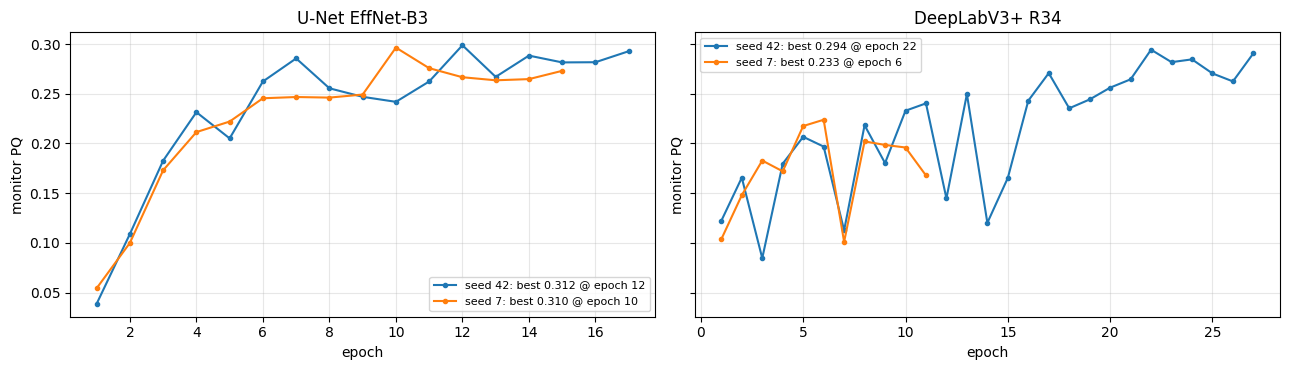

,model,seed,monitor_pq,report_pq,best_epoch,stopped_at,mean_epoch_to_epoch_change,worst_single_epoch_drop
0,U-Net EffNet-B3,seed 42,0.3119,0.3092,12,17,0.029,-0.032
1,U-Net EffNet-B3,seed 7,0.3100,0.3137,10,15,0.020,-0.021
2,DeepLabV3+ R34,seed 42,0.2944,0.3026,22,27,0.046,-0.130
3,DeepLabV3+ R34,seed 7,0.2331,0.2447,6,11,0.040,-0.123


In [7]:
pairs = [("U-Net EffNet-B3", "arch_smp_unet_efficientnet-b3", "seed2_smp_unet_efficientnet-b3"),
         ("DeepLabV3+ R34", "arch_smp_deeplabv3p", "seed2_smp_deeplabv3p")]
rows = []
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, (lab, n1, n2) in zip(ax, pairs):
    for n, s in [(n1, "seed 42"), (n2, "seed 7")]:
        h = pd.read_csv(f"runs/{n}/history.csv"); r = res.set_index("name").loc[n]
        a.plot(h.epoch, h.val_pq, marker="o", ms=3, label=f"{s}: best {r.monitor_pq:.3f} @ epoch {int(r.best_epoch)}")
        rows.append({"model": lab, "seed": s, "monitor_pq": round(r.monitor_pq, 4), "report_pq": round(r.report_pq, 4),
                     "best_epoch": int(r.best_epoch), "stopped_at": int(r.epochs_run),
                     "mean_epoch_to_epoch_change": round(h.val_pq.diff().abs().mean(), 3),
                     "worst_single_epoch_drop": round(h.val_pq.diff().min(), 3)})
    a.set(title=lab, xlabel="epoch", ylabel="monitor PQ"); a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

**Interpretation.**
- **U-Net EfficientNet-B3 is reproducible:** 0.312 vs 0.310 on the monitor images and 0.309 vs 0.314 on the
  report images. The two seeds differ by at most 0.005.
- **DeepLabV3+ is not:** seed 7 collapsed to 0.233 (report 0.245), 0.06 below seed 42. Its validation PQ
  swings violently between epochs (single-epoch drops up to 0.13, vs at most 0.03 for EfficientNet-B3). Seed
  42 only reached its best at epoch 22 after the learning rate had been halved twice; seed 7 hit a bad
  stretch early and early stopping ended it at epoch 11. **Its 0.303 was a lucky run.**
- **Decision: U-Net with an EfficientNet-B3 encoder.** It has the best monitor PQ, it reproduces across
  seeds, and it's the smallest pretrained model (13.2M parameters). U-Net ResNet34 is equally accurate but
  almost twice the size, and its stability across seeds wasn't tested.
- **Lessons and limits:** one run per configuration isn't enough to rank close candidates; the seed alone
  moved DeepLabV3+ by 0.07. We could only afford two seeds for the top two. Patience 5 can also cut short a
  volatile model; a smoother stopping signal (more monitor images, or a moving average) would help that.

## 7. Learning rate check for the winner
**What & why.** The learning rate was a default (3×10⁻⁴). The brief asks for relevant hyperparameters to be
tuned, so we try 3× lower and 3× higher on the winning model, with the same early-stopping rules.

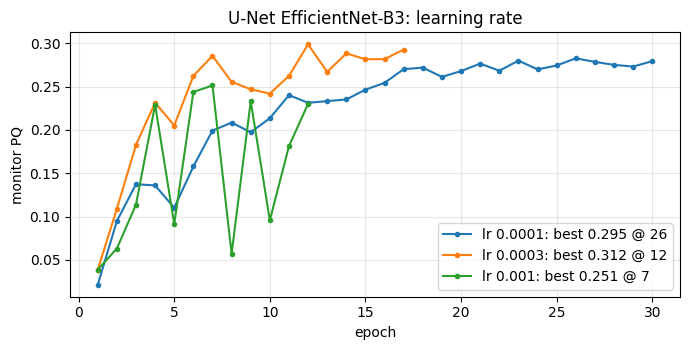

,lr,params_M,lr,seed,best_epoch,epochs_run,monitor_pq,report_pq,report_sq,report_rq,report_tp,report_fp,report_fn,train_minutes
12,0.0001,13.2,0.0001,42,26,30,0.2952,0.3145,0.6687,0.4704,806,1485,330,31.03
5,0.0003,13.2,0.0003,42,12,17,0.3119,0.3092,0.6669,0.4635,785,1466,351,20.68
13,0.0010,13.2,0.0010,42,7,12,0.2514,0.2613,0.6585,0.3968,660,1531,476,12.22


In [8]:
lr_runs = res[res.name.isin(["lr_0.0001_smp_unet_efficientnet-b3", "arch_smp_unet_efficientnet-b3",
                             "lr_0.001_smp_unet_efficientnet-b3"])].sort_values("lr")
fig, ax = plt.subplots(figsize=(7, 3.6))
for _, r in lr_runs.iterrows():
    h = pd.read_csv(f"runs/{r['name']}/history.csv")
    ax.plot(h.epoch, h.val_pq, marker="o", ms=3, label=f"lr {r.lr:g}: best {r.monitor_pq:.3f} @ {int(r.best_epoch)}")
ax.set(xlabel="epoch", ylabel="monitor PQ", title="U-Net EfficientNet-B3: learning rate"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
lr_runs[["lr"] + COLS[1:]].round(4)

**Interpretation.**
- **3×10⁻⁴ is kept.** It has the best monitor PQ (0.312) and reaches it at epoch 12 in 21 minutes.
- **1×10⁻⁴ learns too slowly:** it ran the full 30 epochs without stopping (best at epoch 26) and took 31
  minutes. Its monitor PQ is lower (0.295) but its report PQ is level (0.315 vs 0.309), so the two are tied
  within noise. It costs ~50% more training time for no measured gain, so 3×10⁻⁴ stays.
- **1×10⁻³ is too high:** it's unstable and peaks early and low (0.251 at epoch 7).

## 8. Final configuration on all 5 folds: mean ± std
**What & why.** One validation fold can be lucky. The Results rubric asks for "means and standard deviations
over multiple runs", so the chosen configuration (U-Net EfficientNet-B3, BCE+Dice, learning rate 3×10⁻⁴) is
trained 5 times, each time holding out a different fold. Each model is scored on its fold's report images,
which it never used for early stopping. Fold 0 is the sweep run itself.

In [9]:
cv = json.load(open("runs/cv_5fold.json"))
cvdf = pd.DataFrame(cv["folds"])
print("configuration:", cv["config"])
print(f"5-fold report PQ = {cv['mean']:.4f} ± {cv['std']:.4f} (min {cvdf.report_pq.min():.4f}, max {cvdf.report_pq.max():.4f})")
print("best epochs:", cvdf.best_epoch.tolist())
cvdf.round(4)

configuration: {'arch': 'smp_unet', 'encoder': 'efficientnet-b3', 'loss': 'bce_dice', 'lr': 0.0003}
5-fold report PQ = 0.2975 ± 0.0110 (min 0.2794, max 0.3092)
best epochs: [12, 6, 15, 9, 13]


,fold,name,report_pq,best_epoch,report_pq_v1
0,0,arch_smp_unet_efficientnet-b3,0.3092,12,0.2950
1,1,cv_fold1,0.3021,6,0.2876
2,2,cv_fold2,0.2981,15,0.2833
3,3,cv_fold3,0.2989,9,0.2847
4,4,cv_fold4,0.2794,13,0.2679


**Interpretation.**
- **5-fold PQ = 0.298 ± 0.011** (no post-processing tuning yet, plain threshold 0.5). This is the honest
  estimate of how the chosen configuration performs on unseen solar rotations, as the rubric asks.
- The spread is small: 4 folds lie within 0.298–0.309. Fold 4 is lowest (0.279), but within ~2 standard
  deviations, so no fold behaves strangely. Fold 0 (0.309), where all the choices were made, is the best
  fold, which is a reminder that a single-fold number is slightly optimistic.
- Early stopping picked different epochs per fold (6 to 15), confirming that a fixed epoch count would have
  been wrong for some folds.
- **Caution:** each fold's checkpoint was chosen with the pre-fix (sky) scoring, then re-scored (section 2).

## 9. Post-processing and test-time augmentation
**What & why.** The model outputs probabilities; post-processing turns them into filaments. These settings
cost no training, so we tune them on the chosen model, **on the monitor images only**:
- **threshold:** how confident a pixel must be to count as filament;
- **min_area:** blobs smaller than this many pixels are dropped as noise (each false filament costs ½ in PQ);
- **hysteresis:** keep weaker pixels (down to a lower threshold) only if they connect to a confident one.
  This aims to join fragments of the same filament;
- **closing:** a morphological operation that bridges small gaps before splitting into blobs;
- **TTA (test-time augmentation):** average the predictions over 4 flips of the image.

The tuned settings are then scored once on the report images, with and without TTA.

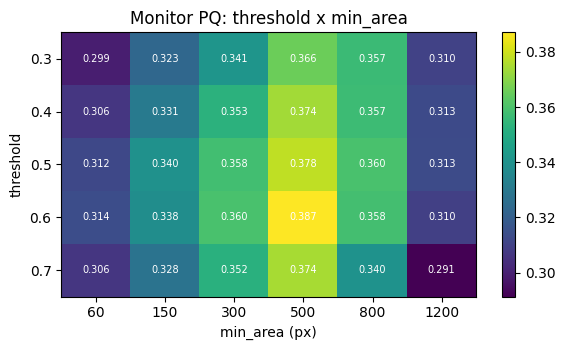

hysteresis / closing (monitor), best first:
 low_threshold  close_px     pq     sq     rq  tp  fp  fn  frag_gt  merge_pred
          -1.0         0 0.3871 0.6630 0.5839 341 252 234       45           9
          -1.0         2 0.3825 0.6639 0.5761 337 258 238       43           9
          -1.0         4 0.3806 0.6630 0.5741 339 267 236       44          13
           0.5         0 0.3778 0.6612 0.5714 342 280 233       43           9
           0.5         4 0.3772 0.6607 0.5709 340 276 235       40          14
           0.4         4 0.3771 0.6565 0.5743 342 274 233       36          16
           0.5         2 0.3763 0.6611 0.5693 339 277 236       43          11
           0.4         0 0.3739 0.6587 0.5676 340 283 235       41          13
           0.4         2 0.3738 0.6591 0.5671 340 284 235       41          14

chosen: threshold 0.6, min_area 500, low_threshold None, close_px 0, TTA True


,setting,tta,seconds_per_image,pq,sq,rq,tp,fp,fn,frag_gt,merge_pred,pred_per_image
0,"default (0.5, 60)",False,0.54,0.3092,0.6669,0.4635,785,1466,351,161,17,14.0
1,tuned,False,0.54,0.3810,0.6709,0.5678,716,670,420,82,16,8.6
2,"default (0.5, 60)",True,1.85,0.3258,0.6705,0.4859,803,1366,333,152,16,13.5
3,tuned,True,1.85,0.3961,0.6731,0.5884,732,620,404,69,15,8.3


In [10]:
g1 = pd.read_csv("runs/pp_grid_threshold_area.csv")
g2 = pd.read_csv("runs/pp_grid_hysteresis_close.csv")
ppr = pd.read_csv("runs/pp_report.csv")
pp = json.load(open("runs/postprocess.json"))
fig, ax = plt.subplots(figsize=(6, 3.6))
hm = g1.pivot(index="threshold", columns="min_area", values="pq")
im = ax.imshow(hm.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(hm.columns)), hm.columns); ax.set_yticks(range(len(hm.index)), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): ax.text(j, i, f"{hm.values[i, j]:.3f}", ha="center", va="center", fontsize=7, color="w")
ax.set(xlabel="min_area (px)", ylabel="threshold", title="Monitor PQ: threshold x min_area"); plt.colorbar(im)
plt.tight_layout(); plt.show()
print("hysteresis / closing (monitor), best first:"); print(g2.round(4).head(9).to_string(index=False))
print(f"\nchosen: threshold {pp['threshold']}, min_area {pp['min_area']}, low_threshold {pp['low_threshold']}, "
      f"close_px {pp['close_px']}, TTA {pp['use_tta']}")
ppr.round(4)

**Interpretation.** Post-processing is the biggest single gain in this milestone, with no retraining.

| Setting (99 report images) | PQ | false filaments | filaments per image |
|---|---|---|---|
| default (threshold 0.5, min_area 60) | 0.309 | 1,466 | 14.0 |
| tuned (threshold 0.6, min_area 500) | 0.381 | 670 | 8.6 |
| tuned + TTA (4 flips) | **0.396** | **620** | 8.3 |

- **The size filter does most of the work.** Dropping predicted blobs under 500 pixels removes more than half
  the false filaments (1,466 → 670). Real filaments are mostly larger than ~300 px (data prep), so the
  small blobs were mostly noise. 500 sits inside the tested grid (60–1,200), so it isn't an edge value.
- **Threshold 0.6** beats 0.5 slightly; higher thresholds start losing real filaments.
- **Hysteresis and closing did not help** (best is "off"). Joining weak pixels to strong ones, or bridging
  small gaps, connected neighbouring blobs more than it repaired broken filaments. So the fragmentation seen
  in section 10 needs a better model, not a simple gap filler.
- **TTA adds +0.015** for 3.4× the inference time (1.85 s vs 0.54 s per image). Kept, because the brief
  rewards accuracy most; it's the first thing to drop if efficiency matters more.
- **Tuned on monitor, confirmed on report:** monitor PQ 0.387, report 0.381 (no TTA), so the tuning
  generalises. SQ stays ~0.67 throughout: post-processing changes *which* blobs we keep, not their outlines.
- **This is above the human level:** two annotators agree at PQ ~0.34. On these images, the model agrees
  with the annotators (pooled) better than they agree with each other.

## 10. What kind of mistakes does the final model make?
**What & why.** To improve the model in the Enhancement milestone we need to know *which* errors dominate:
- **false filaments (FP)** and **missed filaments (FN)**, the two terms that lower RQ;
- **fragmentation:** a real filament overlapped by more than one prediction (one-to-many), so pieces count
  as false filaments and the real one may count as missed;
- **merging:** one prediction overlapping several real filaments (many-to-one);
- whether any **telescope site** is much harder;
- what the **best and worst** report images look like.

In [11]:
W = res.set_index("name").loc[pp["model"]]
cfg = fp.Config(prepared_dir=PREPARED, name=pp["model"], arch=W.arch, encoder=W.encoder, threshold=pp["threshold"],
                min_area=int(pp["min_area"]), low_threshold=pp["low_threshold"], close_px=int(pp["close_px"]), tta=bool(pp["use_tta"]))
per = pd.read_csv(f"runs/pp_per_image_tuned_tta{int(pp['use_tta'])}.csv")
final = ppr[(ppr.setting == "tuned") & (ppr.tta == pp["use_tta"])].iloc[0]
n_gt = int(final.tp + final.fn)
print(f"final setting on the 99 report images: PQ {final.pq:.4f} (SQ {final.sq:.3f} x RQ {final.rq:.3f})")
print(f"real filaments (pooled over annotators) {n_gt}: found {final.tp} ({final.tp / n_gt:.0%}), missed {final.fn}")
print(f"predicted filaments {final.tp + final.fp}: correct {final.tp} ({final.tp / (final.tp + final.fp):.0%}), false {final.fp}")
print(f"fragmented real filaments (>1 prediction overlaps): {final.frag_gt} ({final.frag_gt / n_gt:.0%}); "
      f"merging predictions (overlap >1 real filament): {final.merge_pred}")
print(f"filaments per image: predicted {final.pred_per_image} vs annotators {pp['gt_filaments_per_image']}")
per["iou_sum"] = per.sq * per.tp
site = per.groupby("site")[["iou_sum", "tp", "fp", "fn"]].sum()
site["PQ"] = site.iou_sum / (site.tp + 0.5 * site.fp + 0.5 * site.fn)
site["images"] = per.groupby("site").size()
SITES = {"B": "Big Bear", "C": "Cerro Tololo", "L": "Learmonth", "M": "Mauna Loa", "T": "El Teide", "U": "Udaipur"}
site.index = site.index.map(SITES)
site[["images", "tp", "fp", "fn", "PQ"]].round(3).sort_values("PQ")

final setting on the 99 report images: PQ 0.3961 (SQ 0.673 x RQ 0.588)
real filaments (pooled over annotators) 1136: found 732 (64%), missed 404
predicted filaments 1352: correct 732 (54%), false 620
fragmented real filaments (>1 prediction overlaps): 69 (6%); merging predictions (overlap >1 real filament): 15
filaments per image: predicted 8.3 vs annotators 7.5


,images,tp,fp,fn,PQ
site,,,,,
Mauna Loa,16,92,111,56,0.350
Cerro Tololo,20,140,119,98,0.376
Big Bear,18,148,135,77,0.390
El Teide,14,106,87,57,0.404
Learmonth,17,133,92,70,0.422
Udaipur,14,113,76,46,0.441


**Interpretation.**
- **Final held-out PQ 0.396** (SQ 0.673 × RQ 0.588).
- **The model now finds 64% of the real filaments and 54% of its predictions are real.** It predicts 8.3
  filaments per image vs the annotators' 7.5: much closer than before tuning (14.0), so over-prediction is
  largely fixed.
- **The remaining errors, by size:** 620 false filaments and 404 missed. Fragmentation affects 69 real
  filaments (6%), merging only 15. So most misses are filaments the model doesn't detect at all (faint ones),
  and most false filaments are filament-like dark features, not pieces of real filaments.
- Remember the ceiling: annotators themselves disagree on which faint structures count (human PQ ~0.34),
  so part of the "errors" are structures some annotators drew and others didn't.
- **By site:** every telescope is within 0.35–0.44. **Mauna Loa is hardest (0.350)**; it was also the
  hardest site for the human annotators (data prep §6) and has the most blurry images. Udaipur is easiest
  (0.441). No site needs special handling.

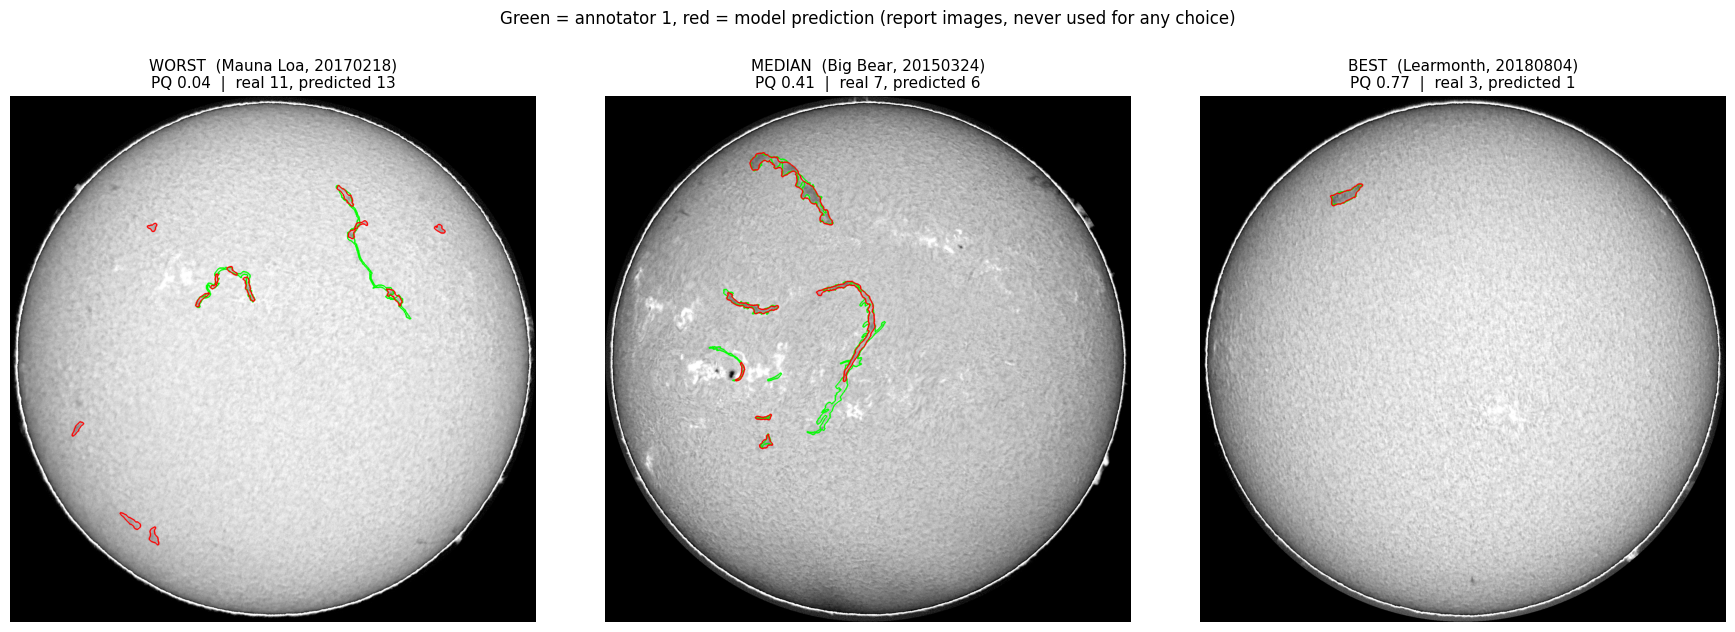

In [12]:
model = fp.load_model(cfg, f"runs/{pp['model']}/best.pt", DEVICE)
cand = per[(per.tp + per.fn) >= 3].sort_values("pq")
picks = [("worst", cand.iloc[0]), ("median", cand.iloc[len(cand) // 2]), ("best", cand.iloc[-1])]
sets = pd.read_csv(Path(PREPARED, "train_observations.csv")).set_index("obs")
fig, ax = plt.subplots(1, 3, figsize=(18, 6.4))
for a, (tag, r) in zip(ax, picks):
    img = np.asarray(fp.load_image(cfg, r.obs))
    inst = fp.prob_to_instances(fp.predict_prob(model, img, cfg, DEVICE), cfg)
    gt_c = cv2.imread(str(Path(PREPARED, "instances", sets.loc[r.obs].set_ids.split("|")[0] + ".png")), cv2.IMREAD_UNCHANGED)
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for m, col in [(gt_c > 0, (0, 255, 0)), (inst > 0, (255, 0, 0))]:
        cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cs, -1, col, 4)
    a.imshow(rgb[100:-100, 100:-100]); a.axis("off")
    a.set_title(f"{tag.upper()}  ({SITES[r.site]}, {r.obs[:8]})\nPQ {r.pq:.2f}  |  real {int(r.tp + r.fn)}, predicted {int(r.n_pred)}", fontsize=11)
fig.suptitle("Green = annotator 1, red = model prediction (report images, never used for any choice)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()

**Interpretation.** (Green = annotator 1, red = model.)
- **Worst (PQ 0.04, Mauna Loa):** the long winding filament on the right is detected only in **pieces**:
  several short red segments along the green outline. No single piece covers over half the filament, so it
  counts as missed *and* the pieces count as false filaments. That's the "structural continuity" difficulty
  the competition names. There are also a few small false blobs on dark patches.
- **Median (PQ 0.41, Big Bear):** the large filaments are traced well, including the long curved one, but
  the **thin, faint tails** (lower right, near the bright active region) are missed or broken.
- **Best (PQ 0.77, Learmonth):** a quiet Sun with one clear filament, traced almost exactly, nothing invented.
- **For the Enhancement milestone:** the clearest target is keeping long, thin filaments in one piece
  (connectivity), and detecting faint thin parts. Simple gap-filling didn't solve it (section 9).

## 11. Submission file, model size and inference time
**What & why.** The brief requires `submission.csv` in the zip and asks us to report model size and
end-to-end inference time. `run_postprocess.py` produced the file with the final model and settings. Here we
check it against the Kaggle format rules: one row per filament, ids `<image>_<k>` that are unique, only test
image names, and RLE counts that decode to 2048×2048 masks.

In [13]:
from pycocotools import mask as mu
sub = pd.read_csv("submission.csv")
test = pd.read_csv(Path(PREPARED, "test_observations.csv"))
stems = sub.filament_id.str.rsplit("_", n=1).str[0]
areas = [int(mu.decode({"size": [2048, 2048], "counts": s.encode()}).sum()) for s in sub.segmentation_rle]
checks = {
    "columns are exactly filament_id, segmentation_rle": list(sub.columns) == ["filament_id", "segmentation_rle"],
    "filament ids unique": sub.filament_id.is_unique,
    "every id refers to a test image": set(stems) <= set(test.obs),
    "no quotes in RLE strings": not sub.segmentation_rle.str.contains("['\"]").any(),
    "every RLE decodes to a non-empty 2048x2048 mask": min(areas) > 0,
}
for k, v in checks.items(): print(("PASS" if v else "FAIL"), k)
print(f"\n{len(sub)} filaments over {stems.nunique()} of {len(test)} test images; "
      f"{len(sub) / len(test):.1f} per image; median filament size {np.median(areas):.0f} px")
ck = Path(f"runs/{pp['model']}/best.pt")
print(f"model: {pp['params'] / 1e6:.1f}M parameters, checkpoint {ck.stat().st_size / 1e6:.0f} MB")
print(f"end-to-end inference on the 180 test images: {pp['submission_seconds']} s ({pp['submission_seconds_per_image']} s per image, "
      f"TTA {pp['use_tta']}), laptop RTX 4060")
print(f"training time of the final model: {W.train_minutes} min")

PASS columns are exactly filament_id, segmentation_rle
PASS filament ids unique
PASS every id refers to a test image
PASS no quotes in RLE strings
PASS every RLE decodes to a non-empty 2048x2048 mask

1474 filaments over 179 of 180 test images; 8.2 per image; median filament size 1201 px
model: 13.2M parameters, checkpoint 53 MB
end-to-end inference on the 180 test images: 379 s (2.11 s per image, TTA True), laptop RTX 4060
training time of the final model: 20.68 min


**Interpretation.**
- **`submission.csv` passes every Kaggle format rule** and is ready to upload: 1,474 filaments, unique ids,
  RLE counts that decode to 2048×2048 masks. It was built with the final model and settings (threshold 0.6,
  min_area 500, TTA).
- One test image (20200310113230Ch) has no predicted filament. That's allowed (Kaggle counts its real
  filaments as missed); it isn't a format error.
- **Model size: 13.2M parameters (53 MB).** **End-to-end inference: 2.1 s per image** (6.3 min for all 180
  test images) on the laptop RTX 4060, including the 4-flip TTA, mapping back to the original frame and RLE
  encoding. Without TTA it's ~0.6 s per image. **Training: 21 minutes.** These are the numbers the brief
  asks us to report, and the baseline for compression experiments.

## Summary: what the experimental setup established

| Question | Answer (evidence) |
|---|---|
| Is the pipeline correct end to end? | **Yes**: 14/14 checks from raw data to metric; our PQ = organisers' PQ (§1) |
| What did the audit change? | 11 faults fixed; a perfect prediction now scores 0.997 instead of 0.864; same model 0.246 → 0.317 (§2) |
| Can we trust choices made on 40 images? | **Yes**: ranking on monitor vs report agrees (Spearman 0.93) (§3) |
| Loss | **BCE+Dice** (0.307 monitor / 0.317 report), ahead of focal+dice, Dice, Tversky (§4) |
| Architecture | **U-Net + EfficientNet-B3**: tied best on accuracy with U-Net ResNet34, 46% smaller (13.2M) (§5) |
| Bare CNN (FCN-32s)? | Worst by far (0.107): a decoder is necessary (§5) |
| Reproducible? | EfficientNet-B3 seeds differ by ≤0.005; DeepLabV3+ varied by 0.06 (§6) |
| Learning rate | 3×10⁻⁴ kept; 1×10⁻⁴ ties but is 50% slower; 1×10⁻³ worse (§7) |
| Epochs | Early stopping: best epoch 6–15 depending on fold, never near the 30 cap (§8) |
| **5-fold PQ** (untuned) | **0.298 ± 0.011** (§8) |
| **Final held-out PQ** | **0.396** with threshold 0.6, min_area 500, flip TTA; above human agreement (~0.34) (§9) |
| Main remaining errors | Missed faint filaments (404), filament-like false detections (620), long filaments broken into pieces (§10) |
| Size / speed | 13.2M params, 53 MB; 2.1 s per test image with TTA; 21 min training (§11) |
| Kaggle file | `submission.csv` passes all format checks (§11) |

**Stated limitations**
- Checkpoints were chosen by early stopping before fault 11 was found, then re-scored rather than retrained.
- Only the top two candidates got a second seed; the 5-fold std (0.011) is the best estimate of noise.
- The final 0.396 uses post-processing tuned on fold 0 only; the 5-fold number (0.298) is before tuning.
- Every number is local. The Kaggle leaderboard score should be checked by uploading `submission.csv`.

**Next (Enhancement milestone):** keep long thin filaments in one piece; recover faint filaments; then
compress the model (the 13.2M-parameter model is the baseline for size/speed comparisons).